In [26]:
# cargamos paquetes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statistics as st
# from scipy import stats as st

In [6]:
# cargamos los datos

df = pd.read_csv('df_2025_MM82_master.csv')

In [7]:
df.columns

Index(['object_names', 'obs_times', 'mag', 'band', 'dist', 'alpha', 'r', 'a',
       'e', 'i', 'omega', 'Omega', 'M', 'H', 'H_Li', 'H_Lg', 'H_Lz', 'H_Lr',
       'H_Ly', 'H_Lu'],
      dtype='object')

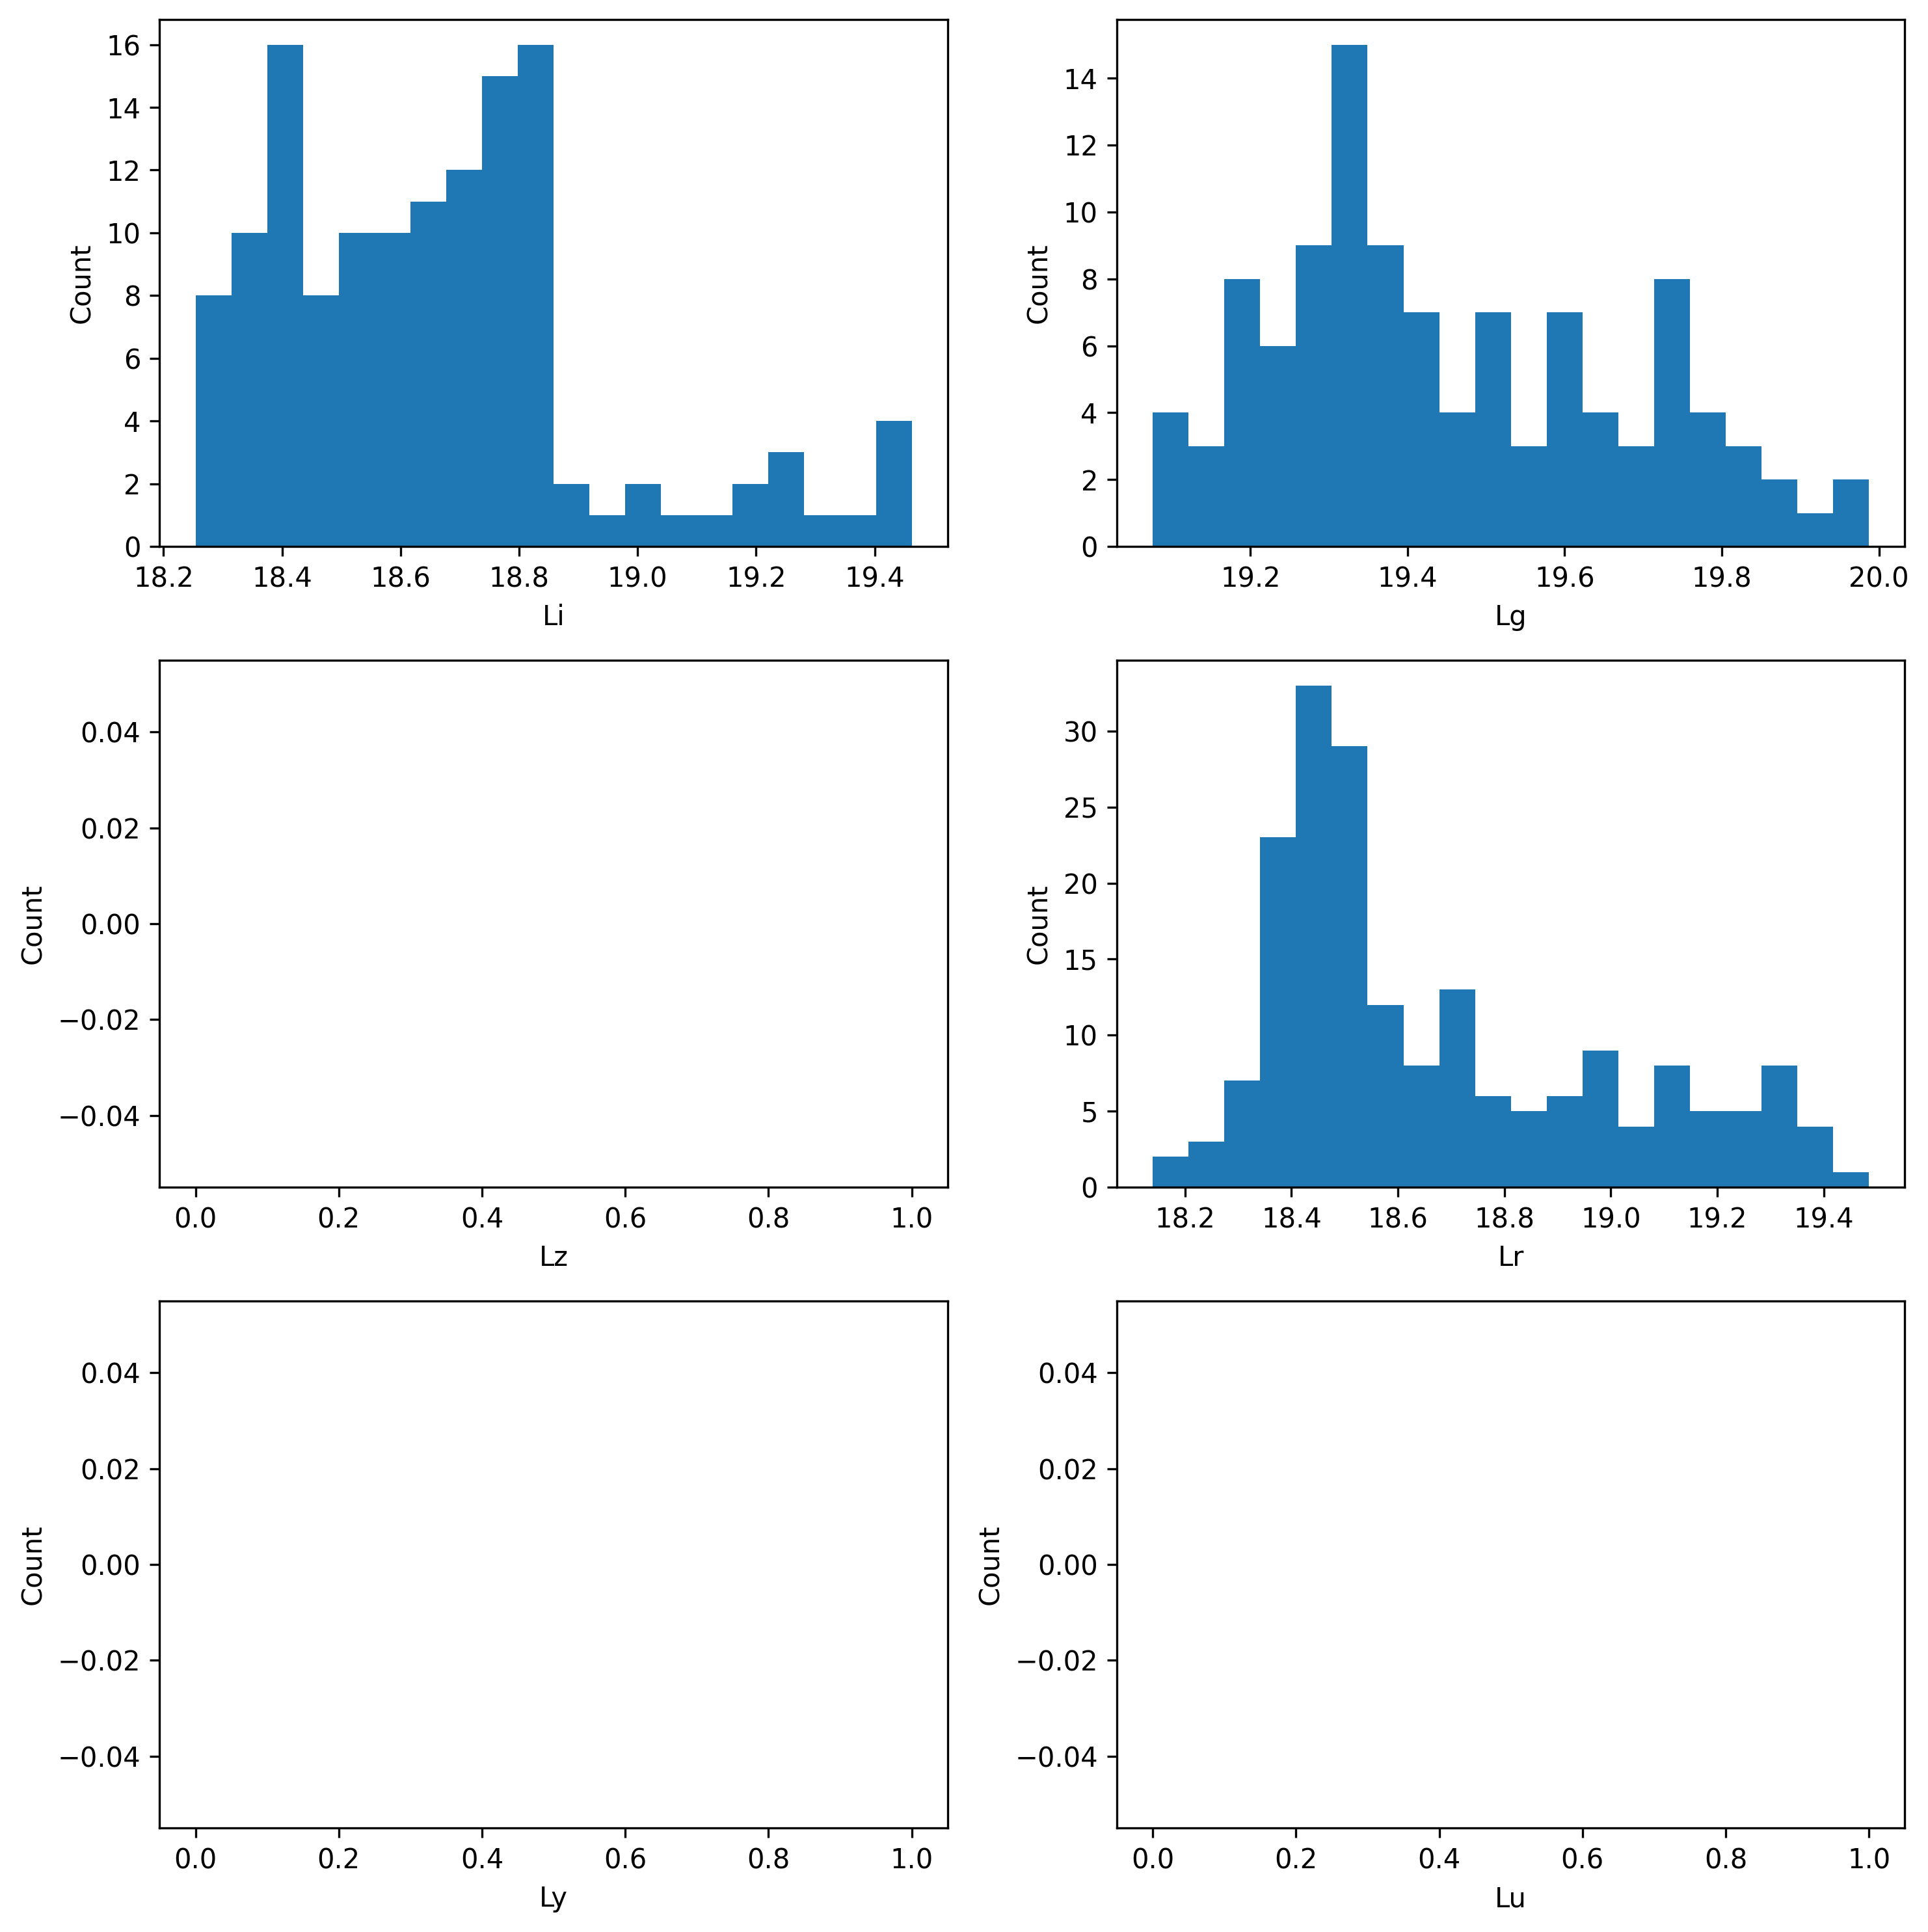

In [12]:

bands = ['Li', 'Lg', 'Lz', 'Lr', 'Ly', 'Lu']

fig, axes = plt.subplots(3, 2, figsize=(10, 10), dpi=300)

for ax, band in zip(axes.flat, bands):
    ax.hist(df[f'H_{band}'].dropna().values, bins=20)
    ax.set_xlabel(band)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

In [37]:
Li = np.nanmean(df.loc[np.isfinite(df.H_Li), 'H_Li'])
Lg = np.nanmean(df.loc[np.isfinite(df.H_Lg), 'H_Lg'])
Lz = np.nanmean(df.loc[np.isfinite(df.H_Lz), 'H_Lz'])
Lr = np.nanmean(df.loc[np.isfinite(df.H_Lr), 'H_Lr'])
Ly = np.nanmean(df.loc[np.isfinite(df.H_Ly), 'H_Ly'])
Lu = np.nanmean(df.loc[np.isfinite(df.H_Lu), 'H_Lu'])

sigma_Li = np.std(df.loc[np.isfinite(df.H_Li), 'H_Li'], ddof=1)
sigma_Lg = np.std(df.loc[np.isfinite(df.H_Lg), 'H_Lg'], ddof=1)
sigma_Lz = np.std(df.loc[np.isfinite(df.H_Lz), 'H_Lz'], ddof=1)
sigma_Lr = np.std(df.loc[np.isfinite(df.H_Lr), 'H_Lr'], ddof=1)
sigma_Ly = np.std(df.loc[np.isfinite(df.H_Ly), 'H_Ly'], ddof=1)
sigma_Lu = np.std(df.loc[np.isfinite(df.H_Lu), 'H_Lu'], ddof=1)

/tmp/ipykernel_1924/3343020157.py:3: RuntimeWarning: Mean of empty slice
  Lz = np.nanmean(df.loc[np.isfinite(df.H_Lz), 'H_Lz'])
/tmp/ipykernel_1924/3343020157.py:5: RuntimeWarning: Mean of empty slice
  Ly = np.nanmean(df.loc[np.isfinite(df.H_Ly), 'H_Ly'])
/tmp/ipykernel_1924/3343020157.py:6: RuntimeWarning: Mean of empty slice
  Lu = np.nanmean(df.loc[np.isfinite(df.H_Lu), 'H_Lu'])


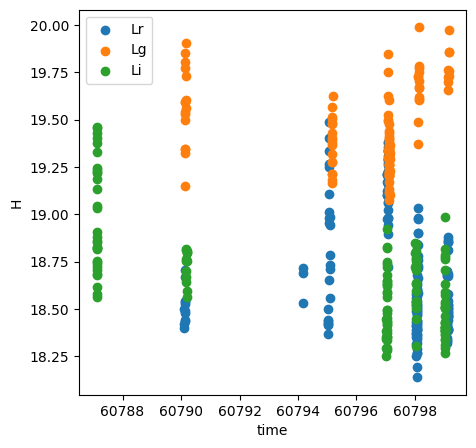

In [20]:
plt.figure(dpi=100, figsize=(5,5))
plt.scatter(df.obs_times, df.H_Lr, label='Lr')
plt.scatter(df.obs_times, df.H_Lg, label='Lg')
plt.scatter(df.obs_times, df.H_Li, label='Li')
plt.xlabel('time')
plt.ylabel('H')
plt.legend()
plt.show()

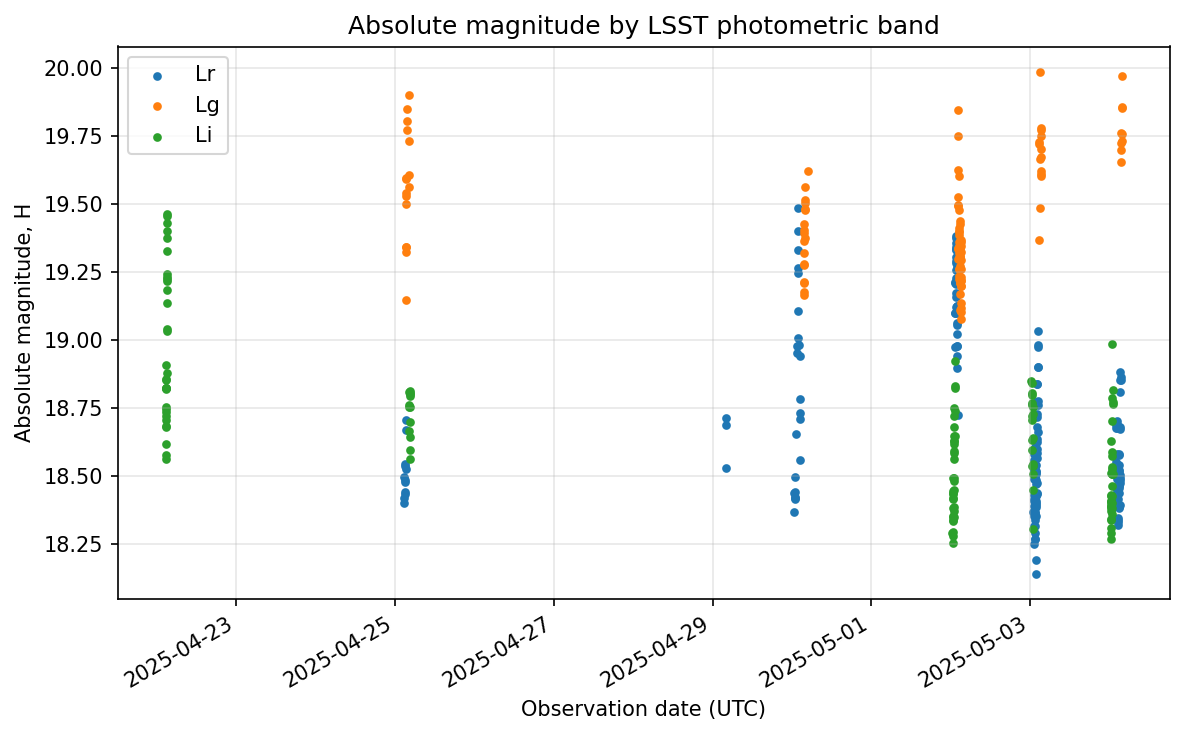

In [21]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from astropy.time import Time

# Convert MJD to datetime (UTC)
df['datetime_utc'] = Time(
    df['obs_times'].values,
    format='mjd',
    scale='utc'
).to_datetime()

fig, ax = plt.subplots(dpi=150, figsize=(8, 5))

for band in ['Lr', 'Lg', 'Li']:
    mask = df[f'H_{band}'].notna() & df['datetime_utc'].notna()
    ax.scatter(
        df.loc[mask, 'datetime_utc'],
        df.loc[mask, f'H_{band}'],
        s=10,
        label=band
    )

ax.set_xlabel('Observation date (UTC)')
ax.set_ylabel('Absolute magnitude, H')
ax.set_title('Absolute magnitude by LSST photometric band')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
fig.autofmt_xdate()

ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

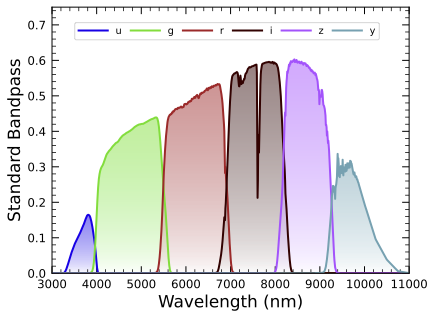

In [42]:
# Para este objeto solamente tenemos las bandas g,r,i por lo que los colores
# que podemos calcular son g-r,r-i,g-i

# Índices de color
g_r = Lg - Lr
r_i = Lr - Li
g_i = Lg - Li

# Incertidumbres propagadas (asumiendo bandas independientes)
sigma_g_r = np.sqrt(sigma_Lg**2 + sigma_Lr**2)
sigma_r_i = np.sqrt(sigma_Lr**2 + sigma_Li**2)
sigma_g_i = np.sqrt(sigma_Lg**2 + sigma_Li**2)

# Imprimir resultados
print(f"g-r = {g_r:.3f} ± {sigma_g_r:.3f}")
print(f"r-i = {r_i:.3f} ± {sigma_r_i:.3f}")
print(f"g-i = {g_i:.3f} ± {sigma_g_i:.3f}")

g-r = 0.781 ± 0.386
r-i = 0.013 ± 0.420
g-i = 0.793 ± 0.353


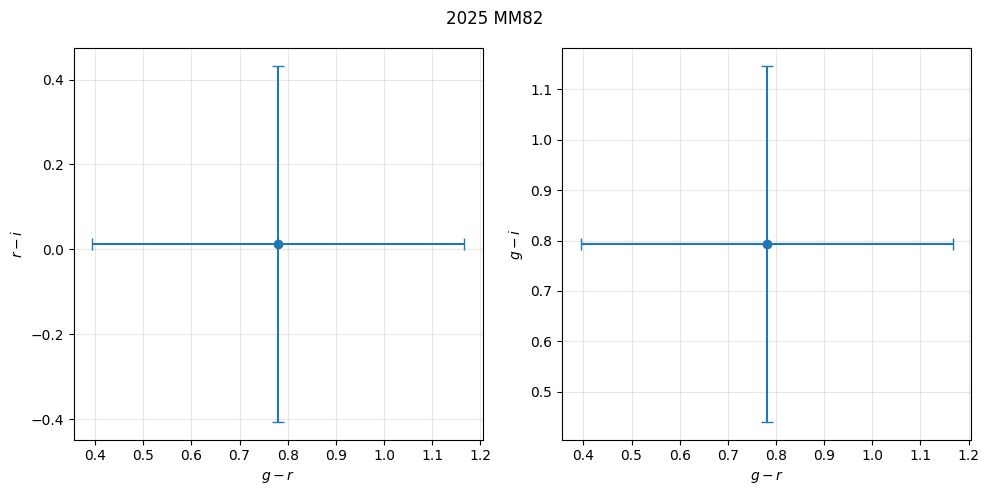

In [43]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, dpi=100, figsize=(10, 5))

# g-r vs r-i
axes[0].errorbar(
    g_r, r_i,
    xerr=sigma_g_r,
    yerr=sigma_r_i,
    fmt='o', capsize=4
)
axes[0].set_xlabel(r'$g-r$')
axes[0].set_ylabel(r'$r-i$')
axes[0].grid(alpha=0.3)

# g-r vs g-i
axes[1].errorbar(
    g_r, g_i,
    xerr=sigma_g_r,
    yerr=sigma_g_i,
    fmt='o', capsize=4
)
axes[1].set_xlabel(r'$g-r$')
axes[1].set_ylabel(r'$g-i$')
axes[1].grid(alpha=0.3)

fig.suptitle('2025 MM82')
plt.tight_layout()
plt.show()